In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from arch import arch_model 
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch 
import warnings

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)

%matplotlib inline


DATA_DIR = Path('data/finance')


if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Data directory not found at: {DATA_DIR.resolve()}")

print(f"Libraries imported and data directory set to: {DATA_DIR.resolve()}")

Libraries imported and data directory set to: /Users/tomaskovac/Desktop/BC/Prílohy INSIS/data/finance


In [ ]:
all_files = list(DATA_DIR.glob('*_data.csv'))


data_dict = {}

print(f"Found {len(all_files)} CSV files to process:")
for file_path in all_files:
    ticker = file_path.stem.split('_')[0]
    print(f"  Loading {file_path.name} for ticker: {ticker}")
    try:
        df = pd.read_csv(file_path, encoding='utf-8-sig')

        date_col = None
        if 'Date' in df.columns:
            date_col = 'Date'
        elif 'Timestamp' in df.columns:
            date_col = 'Timestamp'

        if date_col is None:
            print(f"    Warning: No date column found in {file_path.name}. Skipping.")
            continue

        df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
        df.dropna(subset=[date_col], inplace=True)
        df.set_index(date_col, inplace=True)

        if 'Vol.' in df.columns:
            def parse_volume(vol_str):
                if isinstance(vol_str, str):
                    vol_str = vol_str.strip()
                    if vol_str.endswith('K'):
                        return float(vol_str[:-1]) * 1_000
                    elif vol_str.endswith('M'):
                        return float(vol_str[:-1]) * 1_000_000
                    elif vol_str.endswith('B'):
                        return float(vol_str[:-1]) * 1_000_000_000
                    else:
                        return float(vol_str.replace(',', ''))
                return vol_str
            df['Vol.'] = df['Vol.'].apply(parse_volume)

        if 'Change %' in df.columns:
            df['Change %'] = df['Change %'].str.replace('%', '', regex=False).astype(float)

        if not all(col in df.columns for col in ['Open', 'Price']):
            print(f"    Warning: 'Open' or 'Price' column missing in {file_path.name}. Skipping.")
            continue

        df['Open'] = pd.to_numeric(df['Open'], errors='coerce')
        df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
        df.rename(columns={'Price': 'Close'}, inplace=True)

        df.dropna(subset=['Open', 'Close'], inplace=True)

        df.sort_index(inplace=True)

        data_dict[ticker] = df
        print(f"    Successfully loaded and prepared data for {ticker}. Shape: {df.shape}")

    except Exception as e:
        print(f"    Error processing {file_path.name}: {e}")

data_dict = {k: v for k, v in data_dict.items() if not v.empty}

print(f"\nFinished loading data. Tickers loaded: {list(data_dict.keys())}")
if data_dict:
    first_ticker = list(data_dict.keys())[0]
    print(f"\nSample data for {first_ticker}:")
    display(data_dict[first_ticker].head())
    display(data_dict[first_ticker].info())

Found 6 CSV files to process:
  Loading GOOG_data.csv for ticker: GOOG
    Successfully loaded and prepared data for GOOG. Shape: (253, 6)
  Loading BTC_data.csv for ticker: BTC
    Successfully loaded and prepared data for BTC. Shape: (366, 6)
  Loading TSLA_data.csv for ticker: TSLA
    Successfully loaded and prepared data for TSLA. Shape: (253, 6)
  Loading MSFT_data.csv for ticker: MSFT
    Successfully loaded and prepared data for MSFT. Shape: (253, 6)
  Loading AAPL_data.csv for ticker: AAPL
    Successfully loaded and prepared data for AAPL. Shape: (253, 6)
  Loading AMZN_data.csv for ticker: AMZN
    Successfully loaded and prepared data for AMZN. Shape: (253, 6)

Finished loading data. Tickers loaded: ['GOOG', 'BTC', 'TSLA', 'MSFT', 'AAPL', 'AMZN']

Sample data for GOOG:


,Close,Open,High,Low,Vol.,Change %
Date,,,,,,
2021-09-30,133.27,134.32,135.59,133.00,35360000.0,-0.93
2021-10-01,136.46,133.55,137.07,133.38,28390000.0,2.39
2021-10-04,133.76,135.70,135.70,131.17,31530000.0,-1.98
2021-10-05,136.18,134.00,137.36,134.00,24130000.0,1.81
2021-10-06,137.35,134.63,137.85,134.49,19760000.0,0.86


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 253 entries, 2021-09-30 to 2022-09-30
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Close     253 non-null    float64
 1   Open      253 non-null    float64
 2   High      253 non-null    float64
 3   Low       253 non-null    float64
 4   Vol.      253 non-null    float64
 5   Change %  253 non-null    float64
dtypes: float64(6)
memory usage: 13.8 KB


None

In [ ]:
print("Calculating Log Returns (ln(Close/Open) * 100)...")

for ticker, df in data_dict.items():

    valid_prices = (df['Open'] > 0) & (df['Close'] > 0)


    df['log_return'] = np.nan 
    df.loc[valid_prices, 'log_return'] = np.log(df.loc[valid_prices, 'Close'] / df.loc[valid_prices, 'Open']) * 100

    initial_rows = len(df)
    df.dropna(subset=['log_return'], inplace=True)
    rows_dropped = initial_rows - len(df)

    if df.empty:
        print(f"  {ticker}: No valid log returns could be calculated. Data might be unsuitable.")
    else:
        print(f"  {ticker}: Calculated log returns. Shape after dropping NaNs: {df.shape}. ({rows_dropped} rows dropped)")


data_dict = {k: v for k, v in data_dict.items() if not v.empty}
print(f"\nLog return calculation complete. Tickers with valid returns: {list(data_dict.keys())}")

Calculating Log Returns (ln(Close/Open) * 100)...
  GOOG: Calculated log returns. Shape after dropping NaNs: (253, 7). (0 rows dropped)
  BTC: Calculated log returns. Shape after dropping NaNs: (366, 7). (0 rows dropped)
  TSLA: Calculated log returns. Shape after dropping NaNs: (253, 7). (0 rows dropped)
  MSFT: Calculated log returns. Shape after dropping NaNs: (253, 7). (0 rows dropped)
  AAPL: Calculated log returns. Shape after dropping NaNs: (253, 7). (0 rows dropped)
  AMZN: Calculated log returns. Shape after dropping NaNs: (253, 7). (0 rows dropped)

Log return calculation complete. Tickers with valid returns: ['GOOG', 'BTC', 'TSLA', 'MSFT', 'AAPL', 'AMZN']


Plotting Log Returns over time for each asset...


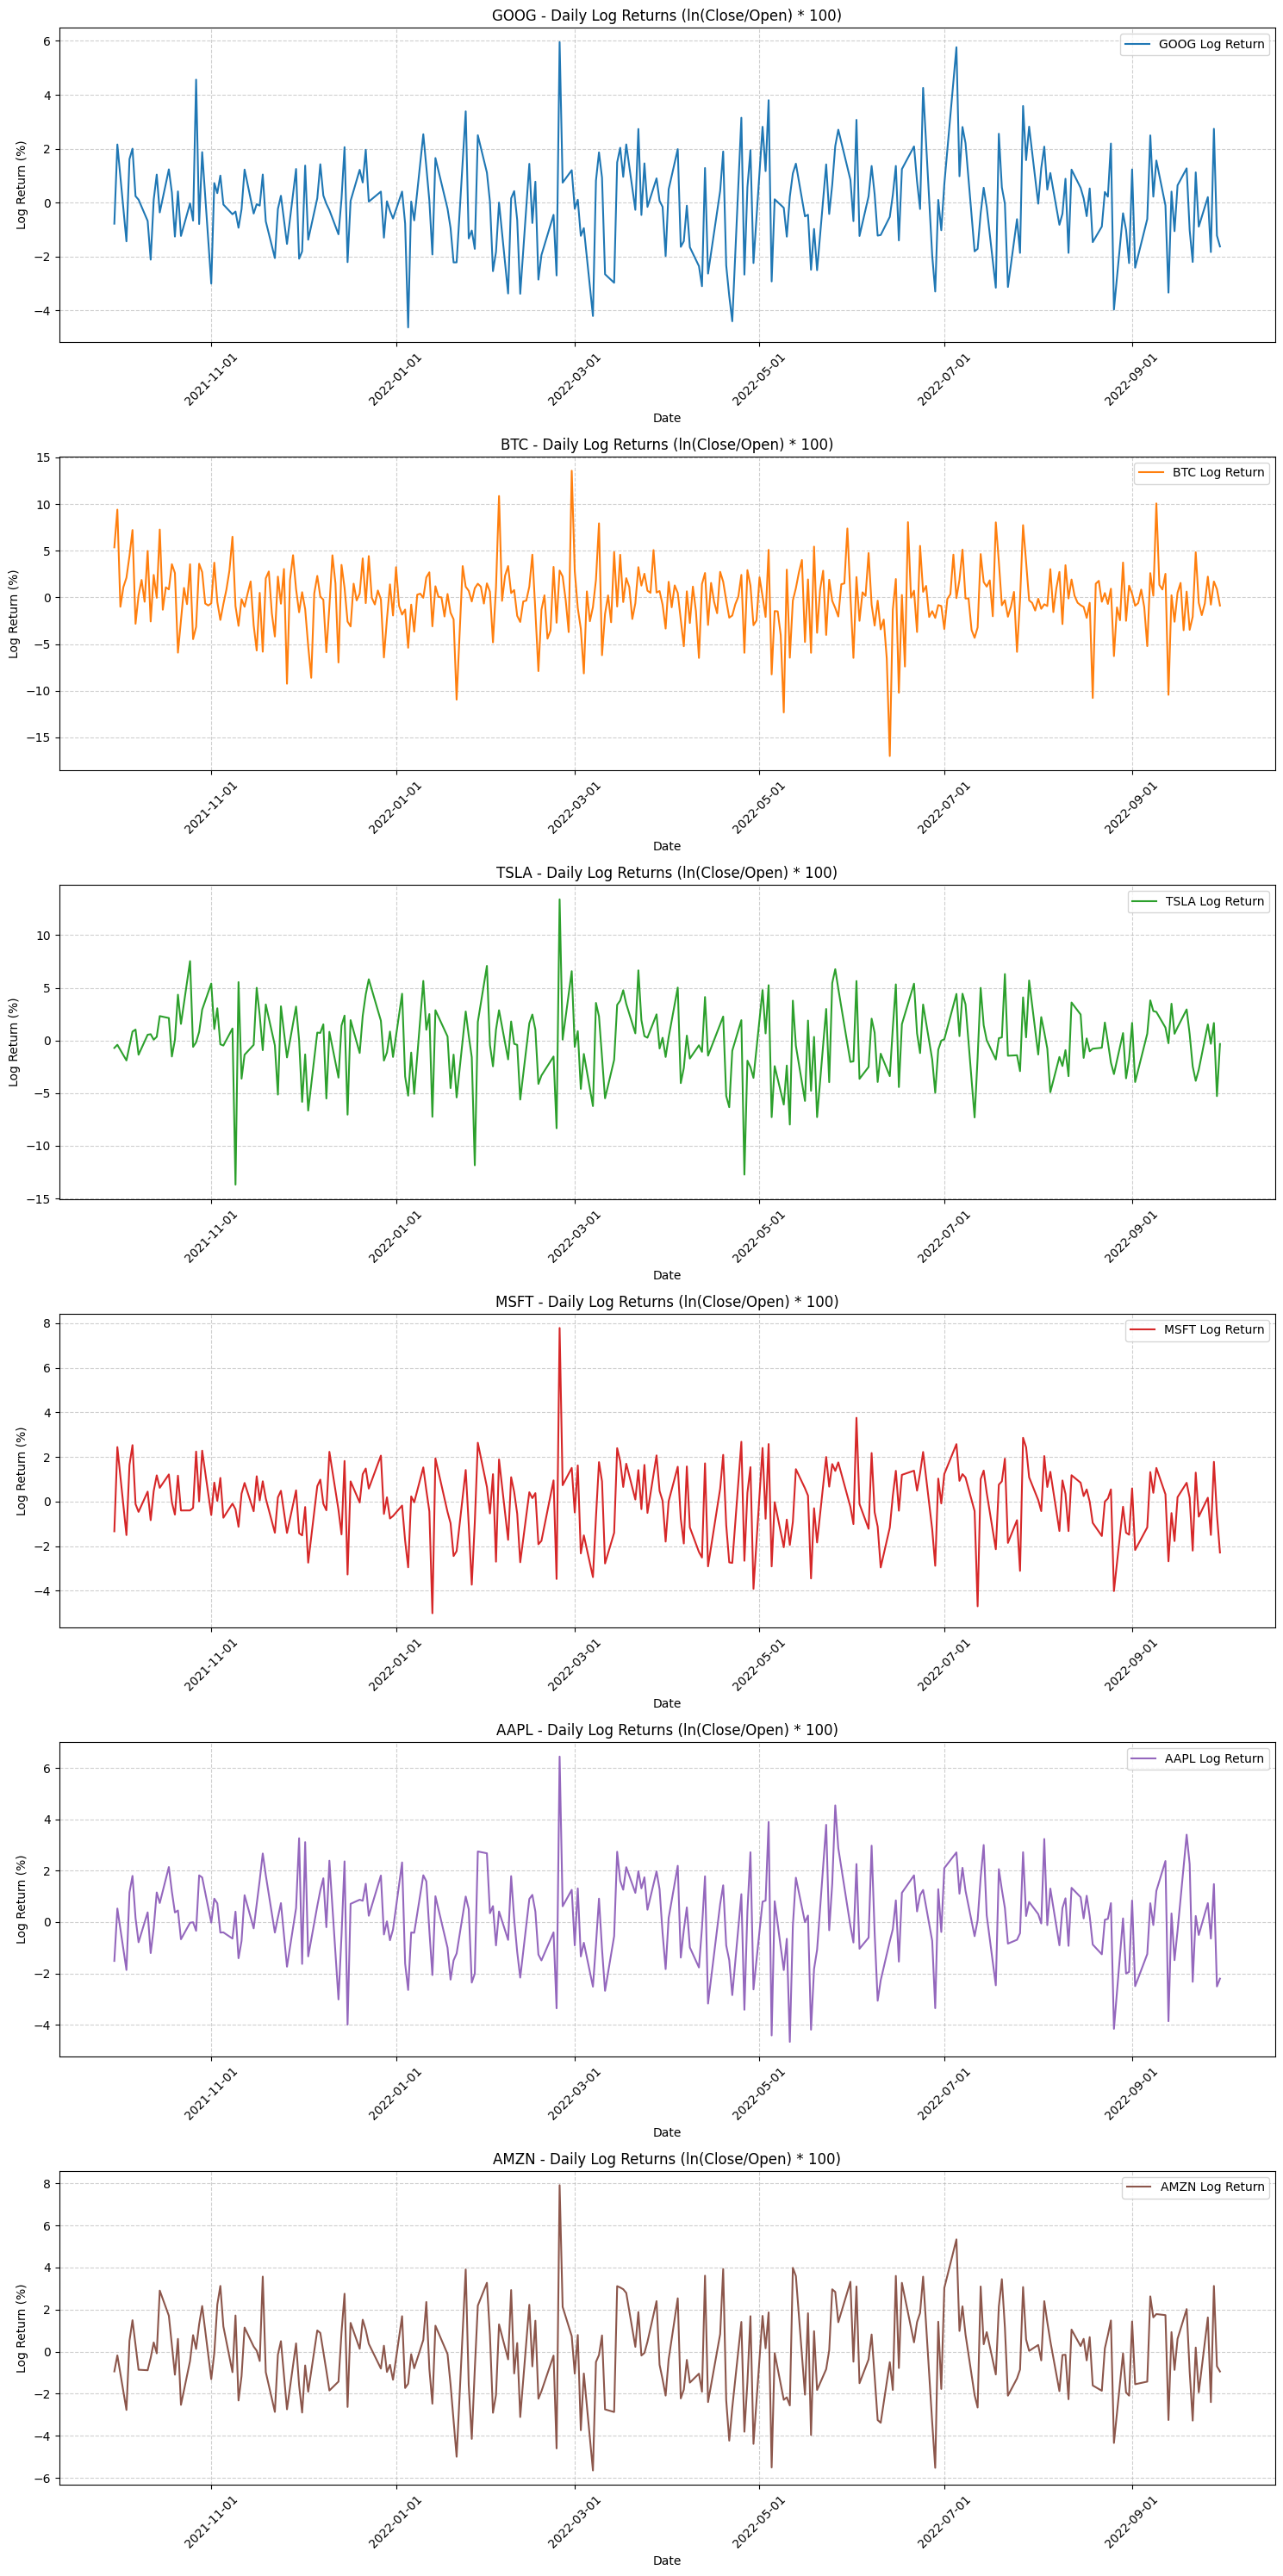

Log return plots displayed.


In [ ]:
print("Plotting Log Returns over time for each asset...")

if not data_dict:
    print("No data available to plot.")
else:
    num_assets = len(data_dict)
    fig, axes = plt.subplots(num_assets, 1, figsize=(15, 5 * num_assets), sharex=True)

    if num_assets == 1:
        axes = [axes]

    for i, (ticker, df) in enumerate(data_dict.items()):
        ax = axes[i]
        ax.plot(df.index, df['log_return'], label=f'{ticker} Log Return', color=f'C{i}')
        ax.set_title(f'{ticker} - Daily Log Returns (ln(Close/Open) * 100)') 
        ax.set_ylabel('Log Return (%)')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend()
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10)) 
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d')) 

        ax.set_xlabel('Date') 
        ax.tick_params(axis='x', labelbottom=True, rotation=45) 




    plt.tight_layout() 
    plt.show()
    print("Log return plots displayed.")

In [ ]:

results_dict = {}

print("Fitting GARCH(1,1) and EGARCH(1,1) models...")

if not data_dict:
    print("No data available for modeling.")
else:
    for ticker, df in data_dict.items():
        print(f"\n--- Modeling {ticker} ---")
        returns = df['log_return'].dropna()

        if returns.empty:
            print(f"  Skipping {ticker}: No valid log return data available after cleaning.")
            continue

        results_dict[ticker] = {}

        try:
            garch_model = arch_model(returns, vol='Garch', p=1, o=0, q=1, mean='Constant', dist='normal')
            garch_results = garch_model.fit(disp='off')
            results_dict[ticker]['garch'] = garch_results
            results_dict[ticker]['garch_sigma_t'] = garch_results.conditional_volatility
            print(f"  {ticker}: GARCH(1,1) fitted successfully.")
        except Exception as e:
            print(f"  Error fitting GARCH(1,1) for {ticker}: {e}")
            results_dict[ticker]['garch'] = None
            results_dict[ticker]['garch_sigma_t'] = None


        try:
            egarch_model = arch_model(returns, vol='Egarch', p=1, o=1, q=1, mean='Constant', dist='normal')
            egarch_results = egarch_model.fit(disp='off')
            results_dict[ticker]['egarch'] = egarch_results
            results_dict[ticker]['egarch_sigma_t'] = egarch_results.conditional_volatility
            print(f"  {ticker}: EGARCH(1,1) fitted successfully.")

        except Exception as e:
            print(f"  Error fitting EGARCH(1,1) for {ticker}: {e}")
            results_dict[ticker]['egarch'] = None
            results_dict[ticker]['egarch_sigma_t'] = None


        results_dict[ticker]['returns'] = returns


    print("\nModel fitting process complete.")

Fitting GARCH(1,1) and EGARCH(1,1) models...

--- Modeling GOOG ---
  GOOG: GARCH(1,1) fitted successfully.
  GOOG: EGARCH(1,1) fitted successfully.

--- Modeling BTC ---
  BTC: GARCH(1,1) fitted successfully.
  BTC: EGARCH(1,1) fitted successfully.

--- Modeling TSLA ---
  TSLA: GARCH(1,1) fitted successfully.
  TSLA: EGARCH(1,1) fitted successfully.

--- Modeling MSFT ---
  MSFT: GARCH(1,1) fitted successfully.
  MSFT: EGARCH(1,1) fitted successfully.

--- Modeling AAPL ---
  AAPL: GARCH(1,1) fitted successfully.
  AAPL: EGARCH(1,1) fitted successfully.

--- Modeling AMZN ---
  AMZN: GARCH(1,1) fitted successfully.
  AMZN: EGARCH(1,1) fitted successfully.

Model fitting process complete.


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


In [ ]:
import numpy as np 
from numpy.linalg import LinAlgError 

print("Performing Residual Diagnostics...")


diagnostics_summary = {}
num_lags = 10 


if not results_dict:
     print("No model results available for diagnostics.")
else:
    for ticker, results in results_dict.items():
        print(f"\n--- Diagnostics for {ticker} ---")
        diagnostics_summary[ticker] = {}

        for model_type in ['garch', 'egarch']:
            model_result = results.get(model_type) 

            if model_result is None:
                print(f"  {model_type.upper()}: Model not available (fitting failed).")
                diagnostics_summary[ticker][model_type] = "Model fitting failed"
                continue

            print(f"\n  {model_type.upper()} Model:")

        
            print(f"--- Summary for {ticker} - {model_type.upper()} ---")
            try:
           
                print(model_result.summary())
            except LinAlgError:
     
                print("!!! Could not generate full summary due to LinAlgError (Singular matrix).")
                print("!!! This often indicates issues with optimization convergence or parameter estimation.")
                print("!!! Displaying estimated parameters only:")

                print(model_result.params)
            except Exception as e:

                 print(f"!!! An unexpected error occurred while generating the summary: {e}")
                 print("!!! Displaying estimated parameters only:")
                 print(model_result.params)

            print("-" * 70) 

            cond_vol = model_result.conditional_volatility
            std_resid = model_result.resid.copy() 
            valid_vol_idx = cond_vol.index[cond_vol.notna() & (cond_vol > 1e-9)] 
            
            if not valid_vol_idx.empty:
                 std_resid.loc[valid_vol_idx] = model_result.resid.loc[valid_vol_idx] / cond_vol.loc[valid_vol_idx]
                 std_resid.loc[std_resid.index.difference(valid_vol_idx)] = np.nan
            else:
                 std_resid[:] = np.nan 

            std_resid.dropna(inplace=True) 


            if std_resid.empty:
                 print("    Skipping diagnostics: No valid standardized residuals available.")
                 diagnostics_summary[ticker][model_type] = "No standardized residuals"
                 continue

            try:
                test_lags = min(num_lags, len(std_resid) - 1)
                if test_lags > 0:
                    lb_resid_df = acorr_ljungbox(std_resid, lags=[test_lags], return_df=True)
                    lb_resid_pvalue = lb_resid_df['lb_pvalue'].iloc[0]
                    print(f"    Ljung-Box Test (Residuals, lags={test_lags}) p-value: {lb_resid_pvalue:.4f}")
                else:
                    print(f"    Ljung-Box Test (Residuals): Not enough data for {num_lags} lags.")
                    lb_resid_pvalue = np.nan

            except Exception as e:
                 print(f"    Ljung-Box Test (Residuals) failed: {e}")
                 lb_resid_pvalue = np.nan


            try:
                test_lags_sq = min(num_lags, len(std_resid) - 1) 
                if test_lags_sq > 0:
                    lb_resid_sq_df = acorr_ljungbox(std_resid**2, lags=[test_lags_sq], return_df=True)
                    lb_resid_sq_pvalue = lb_resid_sq_df['lb_pvalue'].iloc[0]
                    print(f"    Ljung-Box Test (Squared Residuals, lags={test_lags_sq}) p-value: {lb_resid_sq_pvalue:.4f}")
                else:
                     print(f"    Ljung-Box Test (Squared Residuals): Not enough data for {num_lags} lags.")
                     lb_resid_sq_pvalue = np.nan
            except Exception as e:
                 print(f"    Ljung-Box Test (Squared Residuals) failed: {e}")
                 lb_resid_sq_pvalue = np.nan


            diagnostics_summary[ticker][model_type] = {
                f'Ljung-Box (Resid, Lags={num_lags}) p-value': lb_resid_pvalue,
                f'Ljung-Box (Resid^2, Lags={num_lags}) p-value': lb_resid_sq_pvalue,
            }

    try:
  
        valid_summary_data = {
            (i, j): data
            for i, models in diagnostics_summary.items()
            for j, data in models.items()
            if isinstance(data, dict)
        }
        if valid_summary_data:
            summary_df = pd.DataFrame.from_dict(valid_summary_data, orient='index')
            print("\n--- Diagnostics Summary (p-values) ---")
            display(summary_df.round(4)) 
        else:
            print("\nNo valid diagnostic results to display in summary table.")
    except Exception as e:
        print(f"\nCould not create summary DataFrame: {e}")
        print(diagnostics_summary) 


    print("\nResidual diagnostics complete.")

Performing Residual Diagnostics...

--- Diagnostics for AAPL ---

  GARCH Model:
--- Summary for AAPL - GARCH ---
                     Constant Mean - GARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -490.406
Distribution:                  Normal   AIC:                           988.813
Method:            Maximum Likelihood   BIC:                           1002.95
                                        No. Observations:                  253
Date:                Sat, May 03 2025   Df Residuals:                      252
Time:                        01:33:44   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
-----------------------

Ljung-Box (Resid, Lags=10) p-value  \
AAPL garch                               0.9787   
     egarch                              0.9957   
AMZN garch                               0.9396   
     egarch                              1.0000   
BTC  garch                               0.2708   
     egarch                              0.1751   
GOOG garch                               0.9124   
     egarch                              0.9490   
MSFT garch                               0.6627   
     egarch                              0.7809   
TSLA garch                               0.5063   
     egarch                              0.5515   

             Ljung-Box (Resid^2, Lags=10) p-value  
AAPL garch                                 0.9857  
     egarch                                0.9687  
AMZN garch                                 0.8008  
     egarch                                1.0000  
BTC  garch                                 0.9809  
     egarch                                0.8146  
GOOG garch                                 0.8533  
     egarch                                0.7750  
MSFT garch                                 0.9963  
     egarch                                0.9317  
TSLA garch                                 0.9985  
     egarch                                0.9996


Residual diagnostics complete.


Plotting Estimated Conditional Volatility (sigma_t)...


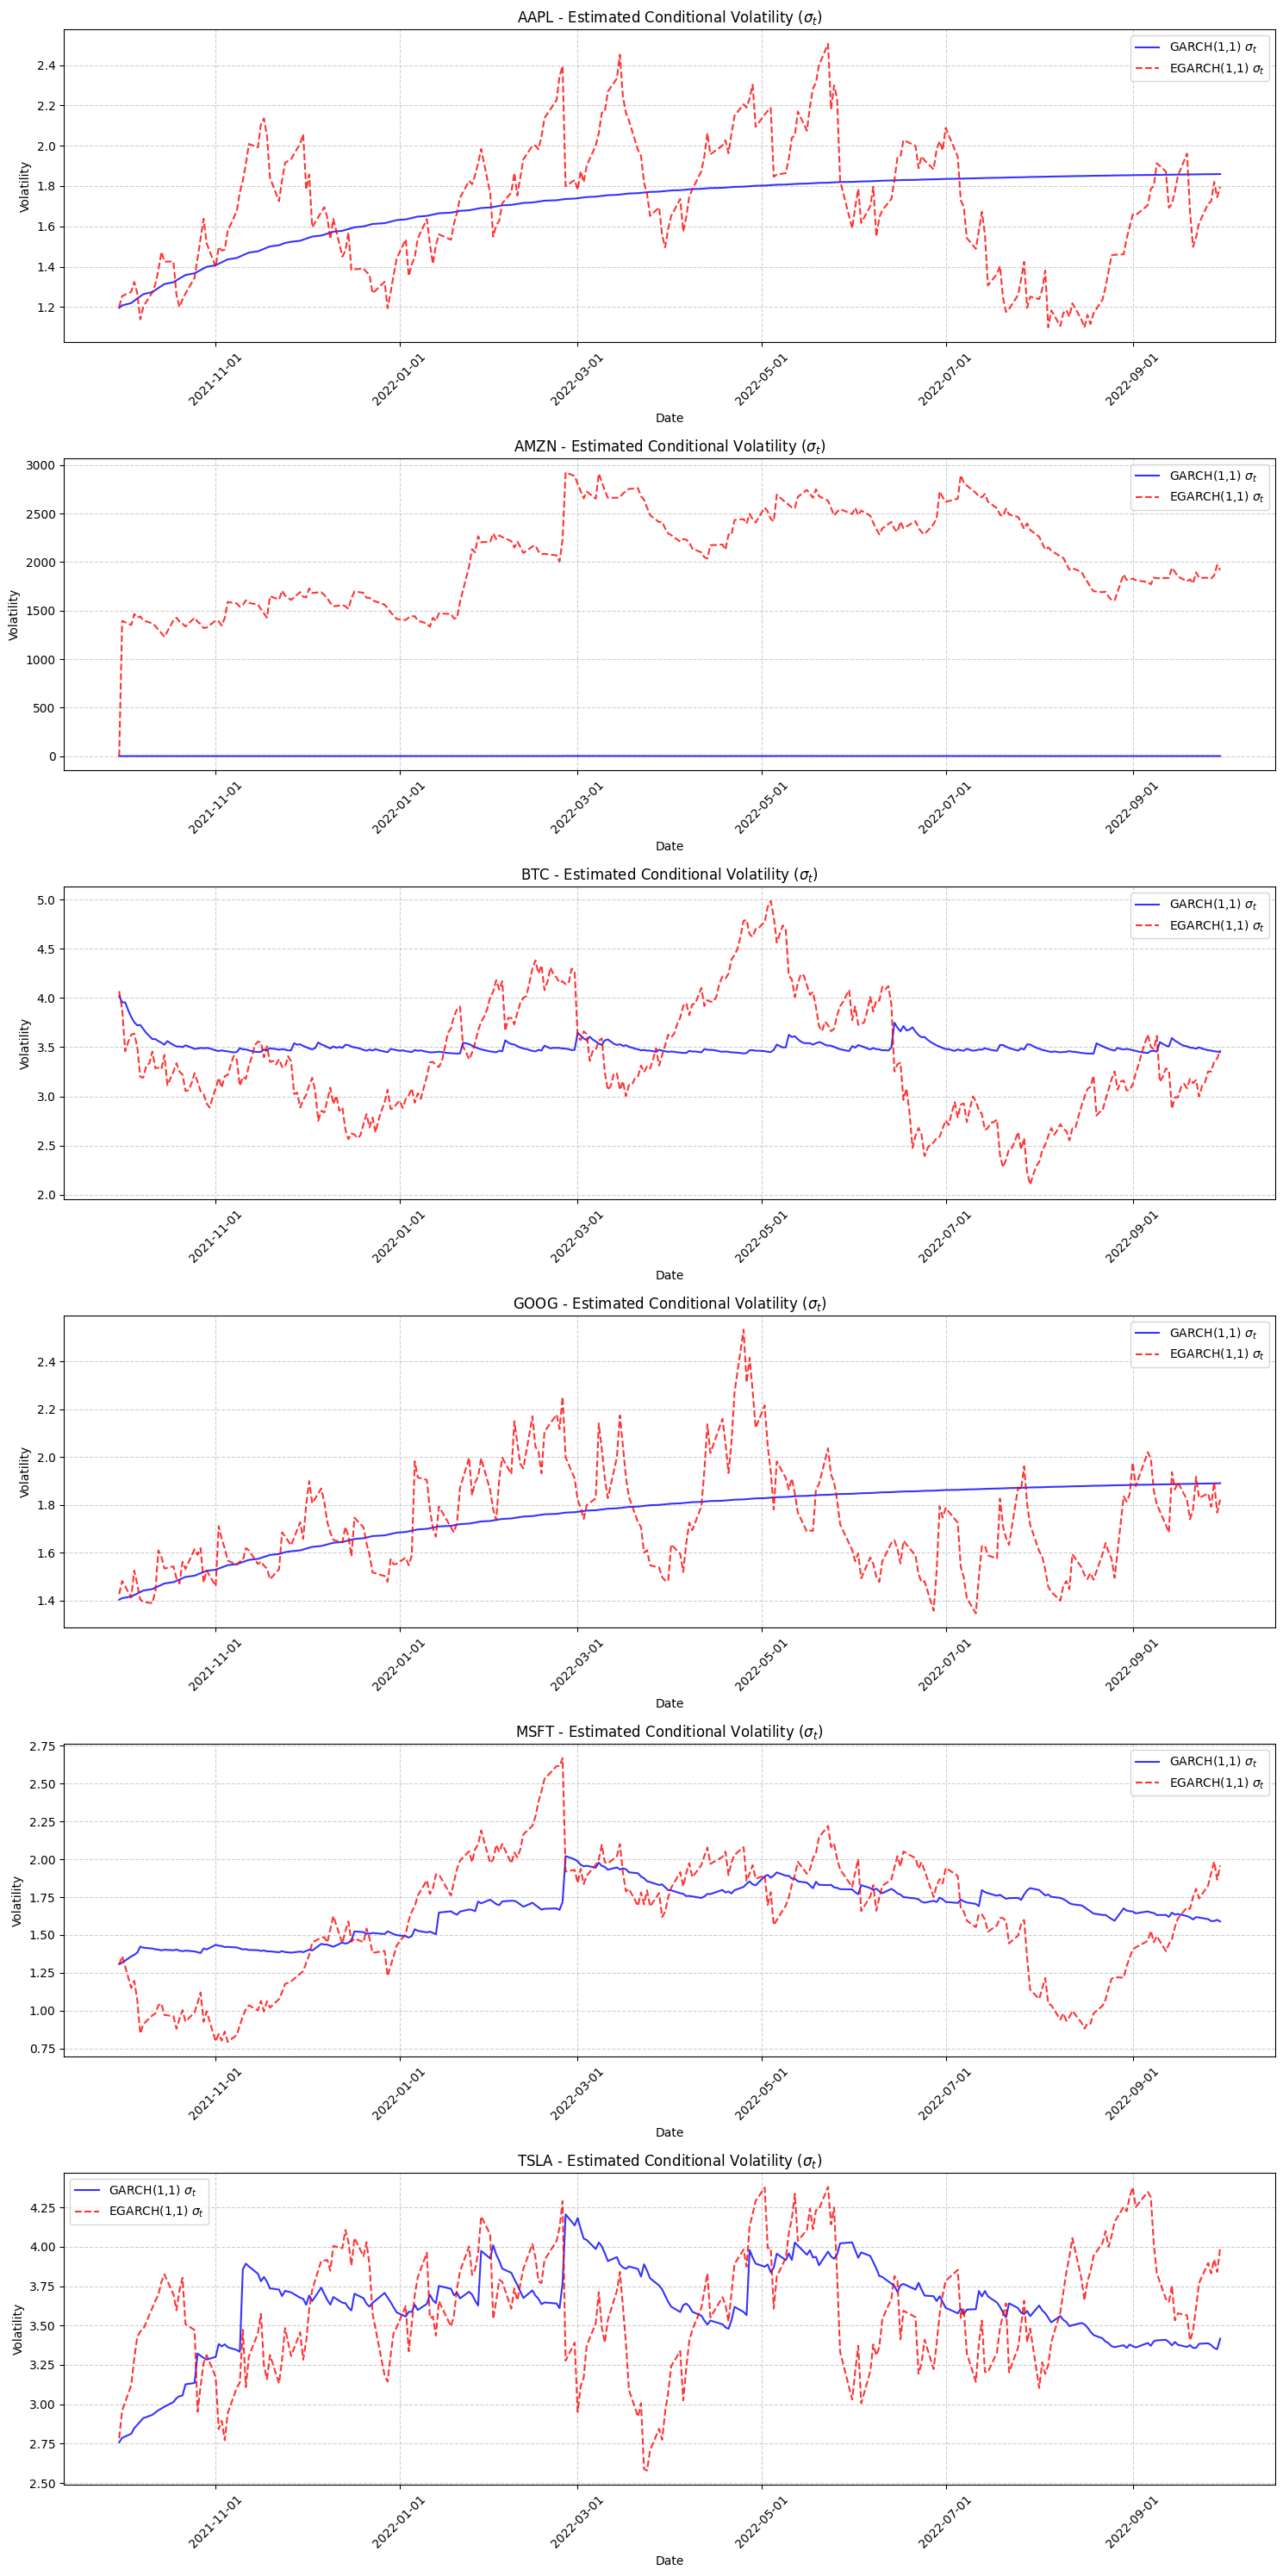

Volatility plots displayed.


In [ ]:
print("Plotting Estimated Conditional Volatility (sigma_t)...")


if not results_dict:
     print("No model results available to plot volatility.")
else:
    num_assets = len(results_dict)

    fig, axes = plt.subplots(num_assets, 1, figsize=(15, 5 * num_assets), sharex=True)

    if num_assets == 1:
        axes = [axes]

    plot_successful = False
    for i, (ticker, results) in enumerate(results_dict.items()):
        ax = axes[i]
        plotted_something = False
        if results.get('garch_sigma_t') is not None and not results['garch_sigma_t'].empty:
            ax.plot(results['garch_sigma_t'], label=f'GARCH(1,1) $\\sigma_t$', color='blue', alpha=0.8)
            plotted_something = True
        if results.get('egarch_sigma_t') is not None and not results['egarch_sigma_t'].empty:
            ax.plot(results['egarch_sigma_t'], label=f'EGARCH(1,1) $\\sigma_t$', color='red', alpha=0.8, linestyle='--')
            plotted_something = True

        if plotted_something:
            ax.set_title(f'{ticker} - Estimated Conditional Volatility ($\\sigma_t$)')
            ax.set_ylabel('Volatility')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend()
            ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

            ax.set_xlabel('Date') 
            ax.tick_params(axis='x', labelbottom=True, rotation=45) 

            plot_successful = True
        else:
            ax.set_title(f'{ticker} - No volatility data to plot')
            ax.text(0.5, 0.5, 'No valid model results', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
            ax.set_xlabel('') 


    if plot_successful:
        plt.tight_layout()
        plt.show()
        print("Volatility plots displayed.")
    else:
        print("No valid volatility data found across all assets to plot.")

        plt.close(fig)